In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv("../data/customer_churn.csv")

print("Dataset shape:", df.shape)

print("\nFirst five records:")
display(df.head())

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

Dataset shape: (7043, 21)

First five records:


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes



Column names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    704

In [2]:
# Step 1: Check duplicate records
print("Duplicate records:", df.duplicated().sum())

# Step 2: Convert TotalCharges to numeric
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

# Step 3: Check missing values
print("\nMissing values after conversion:")
print(df.isnull().sum())

# Step 4: Remove rows with missing TotalCharges
df = df.dropna(subset=["TotalCharges"])

# Step 5: Remove duplicate records
df = df.drop_duplicates()

# Step 6: Check the cleaned dataset
print("\nCleaned dataset shape:", df.shape)

print("\nUpdated data types:")
print(df.dtypes)

Duplicate records: 0

Missing values after conversion:
customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

Cleaned dataset shape: (7032, 21)

Updated data types:
customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
S

In [3]:
# Check customer churn counts
print("Churn counts:")
print(df["Churn"].value_counts())

# Calculate churn percentages
print("\nChurn percentage:")
print(df["Churn"].value_counts(normalize=True) * 100)

# Convert churn values into numbers
df["Churn"] = df["Churn"].map({
    "No": 0,
    "Yes": 1
})

print("\nUpdated churn values:")
print(df["Churn"].value_counts())

Churn counts:
Churn
No     5163
Yes    1869
Name: count, dtype: int64

Churn percentage:
Churn
No     73.421502
Yes    26.578498
Name: proportion, dtype: float64

Updated churn values:
Churn
0    5163
1    1869
Name: count, dtype: int64


In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set chart style
sns.set_theme(style="whitegrid")

print("Visualization libraries imported successfully!")

Visualization libraries imported successfully!


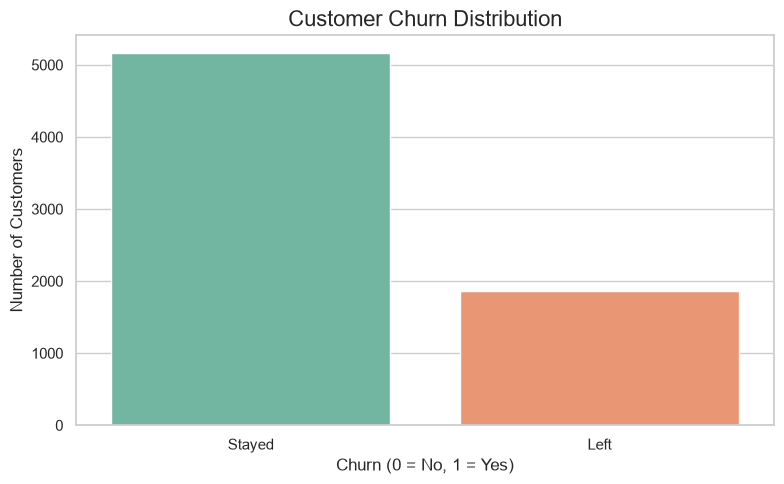

In [5]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Churn",
    hue="Churn",
    palette="Set2",
    legend=False
)

plt.title("Customer Churn Distribution", fontsize=16)
plt.xlabel("Churn (0 = No, 1 = Yes)")
plt.ylabel("Number of Customers")

plt.xticks([0, 1], ["Stayed", "Left"])

plt.tight_layout()
plt.savefig("../visualizations/churn_distribution.png", dpi=300)
plt.show()

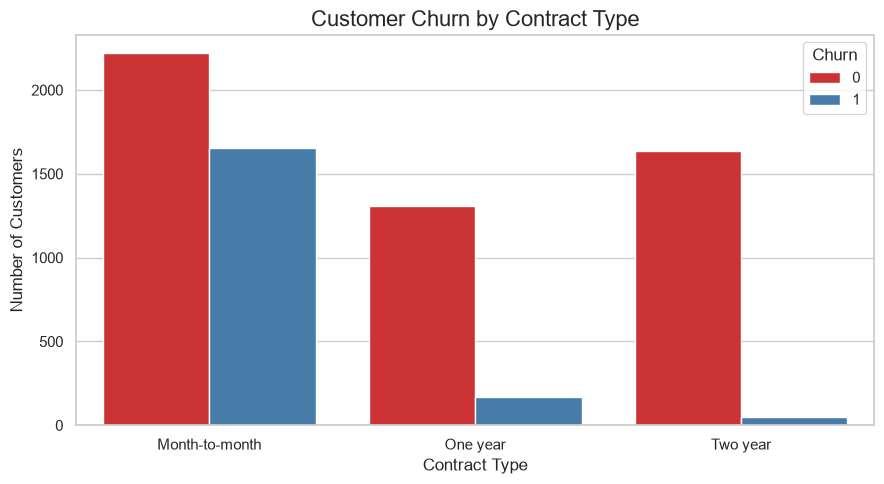

In [6]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="Contract",
    hue="Churn",
    palette="Set1"
)

plt.title("Customer Churn by Contract Type", fontsize=16)
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.savefig("../visualizations/churn_by_contract.png", dpi=300)
plt.show()

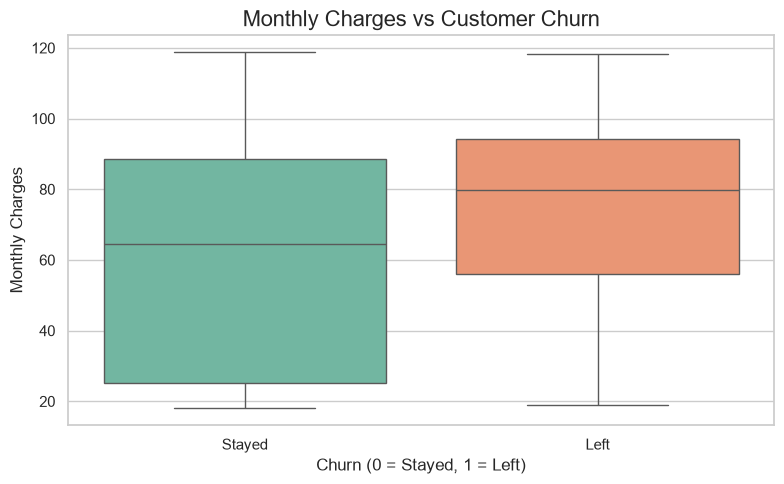

In [7]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="MonthlyCharges",
    hue="Churn",
    palette="Set2",
    legend=False
)

plt.title("Monthly Charges vs Customer Churn", fontsize=16)
plt.xlabel("Churn (0 = Stayed, 1 = Left)")
plt.ylabel("Monthly Charges")

plt.xticks([0, 1], ["Stayed", "Left"])

plt.tight_layout()
plt.savefig("../visualizations/monthly_charges.png", dpi=300)
plt.show()

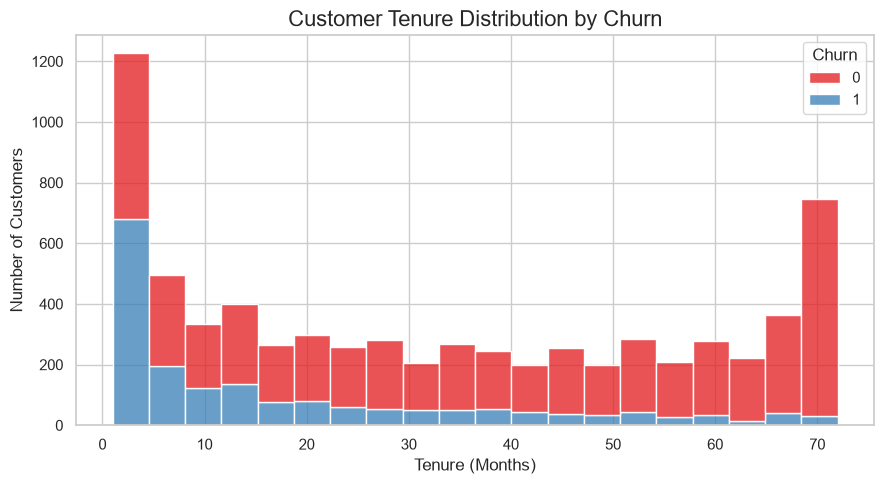

In [8]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="tenure",
    hue="Churn",
    multiple="stack",
    bins=20,
    palette="Set1"
)

plt.title("Customer Tenure Distribution by Churn", fontsize=16)
plt.xlabel("Tenure (Months)")
plt.ylabel("Number of Customers")

plt.tight_layout()

plt.savefig(
    "../visualizations/tenure_analysis.png",
    dpi=300
)

plt.show()

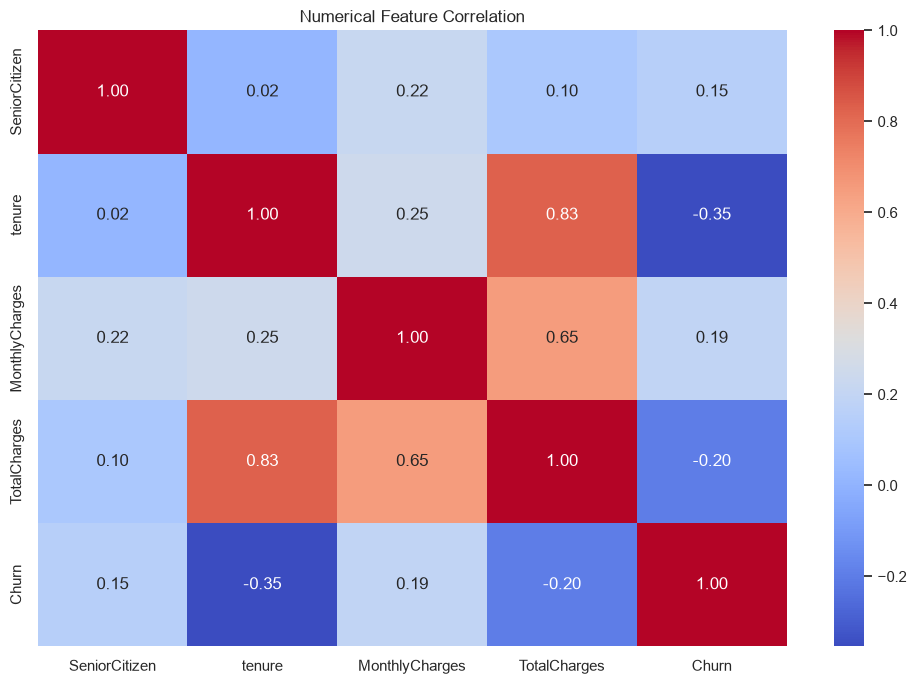

In [9]:
numeric_df = df.select_dtypes(include=np.number)

plt.figure(figsize=(10, 7))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Numerical Feature Correlation")

plt.tight_layout()

plt.savefig(
    "../visualizations/correlation_heatmap.png",
    dpi=300
)

plt.show()